# Sports Retailer Weekly Sales Forecasting — Group 03
**Data Science for Business | Final Assignment | CRISP-DM**

**Dataset:** `group_03_forecasting_3.csv`  
**Analytical unit:** store-week | **Target:** weekly sales in EUR  

This notebook distinguishes **observed dataset facts**, **planning assumptions**, and **analytical decisions**. All reported metrics and charts are generated by executable cells. It is designed to be run from top to bottom.

## 1. Business Understanding

**Business problem.** A multi-store sports retailer needs a defensible estimate of next week's sales by store to support staffing, stock replenishment and short-term planning. The dataset does not provide the retailer's actual costs, inventory, staffing policy or operational targets; the business use case is therefore a **proposed scenario**, not an asserted company fact.

**Stakeholders and decision.** Store managers and central planners review a weekly EUR sales forecast for each store before the coming week. They can use the forecast to flag stores requiring closer manual planning; the forecast is not an automated purchase order.

**Prediction moment.** At the end of week *t*, predict sales in week *t+1*. Only completed sales history and genuinely pre-announced information may be used. The realized temperature, rain, footfall, next-week returns and after-week manager classification are not available at that moment. `average_price_eur` is also excluded because its availability as a pre-week plan is not established.

**Scope.** One-week-ahead, store-level forecasts for stores and dates present in the file; no claims about new stores or other retailers.

**Provisional success criteria (analyst assumptions, not company requirements).** Compare against the same-store last-week-sales naive forecast. Prefer a candidate with at least **5% lower test MAE** and no material deterioration for individual stores; treat these thresholds as discussion aids, not validated financial ROI. Report MAE (EUR), WAPE (aggregate relative error), bias and store-level errors. A business pilot, rather than automatic deployment, is the maximum recommendation without operational cost evidence.

**Critical assumptions.** Weekly sales are an imperfect proxy for demand (stockouts and returns accounting are unknown); there is no documented future promotion schedule; historical relationships may shift. Therefore, we deliberately rely on sales lags and calendar information, not potentially unknown future covariates.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA = Path('group_03_forecasting_3.csv')
if not DATA.exists():
    DATA = Path('/mnt/data/group_03_forecasting_3.csv')
raw = pd.read_csv(DATA)
print('Dataset shape:', raw.shape)
display(raw.head())

Dataset shape: (1065, 11)


,store_id,week_start,promo_label,holiday_week,temperature_actual,rain_mm_actual,footfall_actual,average_price_eur,sales_eur,returns_next_week_eur,manager_sales_band_after_week
0,S06,25-11-2024,NONE,0,11.2,10.5,6875,27.82,36396.09,1279.27,medium
1,S02,22-07-2024,none,0,21.6,6.5,9128,19.57,46580.82,2236.76,high
2,S08,04-03-2024,Discount,0,2.9,0.6,7825,38.01,38589.62,1048.21,medium
3,S02,09-03-2026,discount,0,3.5,5.4,8791,30.29,45311.63,3250.33,high
4,S06,02-12-2024,none,1,1.2,0.4,8382,40.54,37143.15,1487.54,medium


## 2. Data Understanding

The **key should be (`store_id`, `week_start`)**, and the target is `sales_eur`. Examine the key rather than assuming it is unique. The date strings are day-first. `promo_label` is categorical and has inconsistent capitalization; missing values are not automatically equivalent to no promotion. Actual weather, actual footfall, subsequent returns and the after-week band are useful for descriptive context but are **not legitimate future predictors** at the stated prediction moment. This is a temporal availability constraint, not merely a statistical correlation concern.

In [2]:
df = raw.copy()
df['week_start'] = pd.to_datetime(df['week_start'], dayfirst=True, errors='coerce')
print('Date range:', df.week_start.min(), 'to', df.week_start.max())
print('Stores:', df.store_id.nunique(), '| weeks:', df.week_start.nunique())
print('Missing by field:'); display(df.isna().sum().to_frame('missing'))
print('Duplicate store-week rows:', df.duplicated(['store_id','week_start']).sum())
print('Promo raw labels:'); display(df.promo_label.value_counts(dropna=False).to_frame('count'))
print('Sales distribution:'); display(df.sales_eur.describe().to_frame('sales_eur'))
print('Non-positive sales:', (df.sales_eur <= 0).sum())
print('Date parse failures:', df.week_start.isna().sum())

Date range: 2024-01-01 00:00:00 to 2026-03-30 00:00:00
Stores: 9 | weeks: 118
Missing by field:


,missing
store_id,0
week_start,0
promo_label,71
holiday_week,0
temperature_actual,0
rain_mm_actual,0
footfall_actual,0
average_price_eur,18
sales_eur,0
returns_next_week_eur,0


Duplicate store-week rows: 3
Promo raw labels:


,count
promo_label,
none,470
discount,272
bundle,133
Discount,94
NaN,71
NONE,25


Sales distribution:


,sales_eur
count,1065.000000
mean,36832.336342
std,9816.546981
min,3791.040000
25%,32675.260000
50%,36118.020000
75%,42894.250000
max,169869.006000


Non-positive sales: 0
Date parse failures: 0


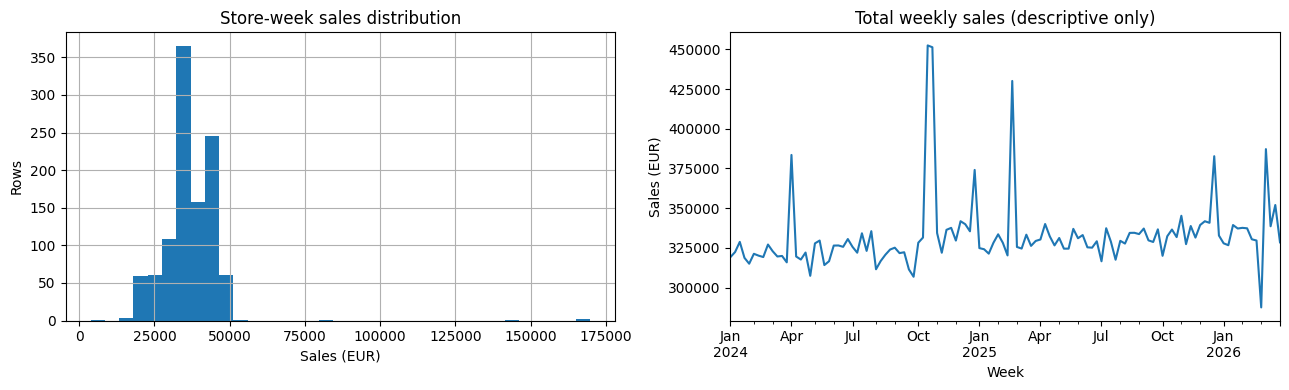

,count,mean,std,min,max
store_id,,,,,
S01,118,23082.44,5828.56,15809.59,80249.73
S02,119,45264.85,2155.83,39702.37,51059.85
S03,119,44741.58,11784.47,38473.75,169869.01
S04,118,35014.10,2198.38,28560.63,39736.14
S05,118,36673.81,2048.00,31185.51,41570.41
S06,118,34242.49,2185.74,29293.19,39723.21
S07,118,31319.16,2150.83,25027.86,36876.30
S08,118,36289.24,10058.92,30639.98,142447.10
S09,119,44658.54,12114.34,3791.04,166970.21


In [3]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
df.sales_eur.hist(ax=axes[0],bins=35)
axes[0].set(title='Store-week sales distribution',xlabel='Sales (EUR)',ylabel='Rows')
df.groupby('week_start').sales_eur.sum().sort_index().plot(ax=axes[1])
axes[1].set(title='Total weekly sales (descriptive only)',xlabel='Week',ylabel='Sales (EUR)')
plt.tight_layout(); plt.show()
display(df.groupby('store_id').sales_eur.agg(['count','mean','std','min','max']).round(2))

### Evidence-based interpretation

The preceding tables quantify missing values, label inconsistencies, key collisions, sales variation and time coverage. These findings refine the business plan: duplicate store-weeks require an explicit resolution, and lagged predictors must be computed on a clean, time-ordered panel. The dataset cannot establish whether spikes arise from promotions, inventory constraints or recording errors; do not assign causal explanations from the plots alone.

## 3. Data Preparation

Three substantive decisions are documented as **evidence → technique → verification → interpretation → next step**:

1. **Duplicate store-week keys:** check conflicting rows, then aggregate sales using the mean within duplicate keys (a conservative provisional resolution; totals could double-count the same observation). Verify uniqueness after resolution. If duplicates reflect distinct legitimate transactions, this assumption must be revisited with the data owner.
2. **Missing/inconsistent descriptive inputs:** standardize `promo_label` case, retain missing as `unknown`, and inspect missing `average_price_eur`; exclude both from modeling because pre-week availability is unverified. Verify missingness and categories after standardization. No post-period information is used to impute predictive features.
3. **Feature inclusion/engineering:** exclude actual target-week weather, footfall, next-week returns and after-week sales band. Create only prior completed weekly sales lags, a trailing mean shifted one week, store identity and deterministic calendar features. Verify lags against source history and remove initial rows with unavailable lag history.

**Temporal safeguards:** all features for week *w* are built from weeks strictly before *w*. Training/validation/test are split by calendar time, not randomly. Hyperparameters and model choice are judged on validation; the test set is evaluated only after choosing the candidate.

In [4]:
before = len(df)
conflicts = df.loc[df.duplicated(['store_id','week_start'],keep=False)].sort_values(['store_id','week_start'])
print('Duplicate-key source rows:'); display(conflicts)
df['promo_clean'] = df.promo_label.astype('string').str.strip().str.lower().fillna('unknown')
print('Promo categories after standardization:'); display(df.promo_clean.value_counts())
print('Missing prices before exclusion:', df.average_price_eur.isna().sum())
# Explicit provisional deduplication; non-target fields are not used as predictors.
panel = (df.groupby(['store_id','week_start'],as_index=False)
         .agg(sales_eur=('sales_eur','mean'))
         .sort_values(['store_id','week_start']).reset_index(drop=True))
assert not panel.duplicated(['store_id','week_start']).any()
print('Rows before / after:', before, len(panel))
print('Key duplicates after:',panel.duplicated(['store_id','week_start']).sum())
print('Dates per store:',panel.groupby('store_id').week_start.nunique().to_dict())

Duplicate-key source rows:


,store_id,week_start,promo_label,holiday_week,temperature_actual,rain_mm_actual,footfall_actual,average_price_eur,sales_eur,returns_next_week_eur,manager_sales_band_after_week
3,S02,2026-03-09,discount,0,3.5,5.4,8791,30.29,45311.63,3250.33,high
151,S02,2026-03-09,discount,0,3.5,5.4,8791,30.29,45311.63,2984.26,high
220,S03,2024-12-30,discount,1,5.2,5.9,8777,18.94,45473.27,1281.35,high
760,S03,2024-12-30,discount,1,5.2,5.9,8777,18.94,45473.27,2950.96,high
848,S09,2025-12-22,none,0,2.4,5.1,9142,25.58,44110.71,654.19,high
993,S09,2025-12-22,none,0,2.4,5.1,9142,25.58,44110.71,1361.44,high


Promo categories after standardization:


promo_clean
none        495
discount    366
bundle      133
unknown      71
Name: count, dtype: Int64

Missing prices before exclusion: 18
Rows before / after: 1065 1062
Key duplicates after: 0
Dates per store: {'S01': 118, 'S02': 118, 'S03': 118, 'S04': 118, 'S05': 118, 'S06': 118, 'S07': 118, 'S08': 118, 'S09': 118}


In [5]:
panel['week_number'] = panel.week_start.dt.isocalendar().week.astype(int)
panel['month'] = panel.week_start.dt.month
panel['week_sin'] = np.sin(2*np.pi*panel.week_number/52.18)
panel['week_cos'] = np.cos(2*np.pi*panel.week_number/52.18)
g = panel.groupby('store_id',sort=False)['sales_eur']
for lag in [1,2,4,8]: panel[f'lag_{lag}'] = g.shift(lag)
panel['trailing_4_mean'] = panel.groupby('store_id',sort=False)['sales_eur'].transform(lambda x: x.shift(1).rolling(4).mean())
print('Lag verification (first 10 rows of one store):')
display(panel.loc[panel.store_id == panel.store_id.iloc[0],['week_start','sales_eur','lag_1','lag_2','trailing_4_mean']].head(10))
model_data = panel.dropna(subset=['lag_1','lag_2','lag_4','lag_8','trailing_4_mean']).copy()
assert (model_data['lag_1'] != model_data['sales_eur'].shift(0)).any()
print('Rows eligible after historical lag warm-up:',len(model_data))
print('Missing predictive features:',model_data[['lag_1','lag_2','lag_4','lag_8','trailing_4_mean']].isna().sum().sum())

Lag verification (first 10 rows of one store):


,week_start,sales_eur,lag_1,lag_2,trailing_4_mean
0,2024-01-01,21393.60,NaN,NaN,NaN
1,2024-01-08,18429.52,21393.60,NaN,NaN
2,2024-01-15,21566.87,18429.52,21393.60,NaN
3,2024-01-22,20068.53,21566.87,18429.52,NaN
4,2024-01-29,19925.60,20068.53,21566.87,20364.6300
5,2024-02-05,20948.10,19925.60,20068.53,19997.6300
6,2024-02-12,18963.15,20948.10,19925.60,20627.2750
7,2024-02-19,21453.58,18963.15,20948.10,19976.3450
8,2024-02-26,22086.19,21453.58,18963.15,20322.6075
9,2024-03-04,23120.25,22086.19,21453.58,20862.7550


Rows eligible after historical lag warm-up: 990
Missing predictive features: 0


## 4. Modelling

**Baseline:** same-store last week's sales (`lag_1`). This is available at the prediction moment and is a meaningful operational hurdle.

**Candidate:** a regularized histogram gradient boosting regressor, using only prior-week sales history, deterministic calendar features and one-hot store indicators. This accommodates nonlinear seasonal and lag interactions without requiring target-week realized covariates. The model is not presumed superior to the naive baseline.

**Validation design:** chronological cutoffs at approximately 65% (train) and 80% (validation) of unique eligible weeks; the latest 20% is held out for final testing. All stores share the same calendar cutoffs. Candidate tuning uses the validation period only. These are single contiguous blocks, not rolling cross-validation, so performance uncertainty remains.

In [6]:
dates = np.array(sorted(model_data.week_start.unique()))
cut1, cut2 = dates[int(len(dates)*0.65)], dates[int(len(dates)*0.80)]
train = model_data[model_data.week_start < cut1].copy()
val = model_data[(model_data.week_start >= cut1)&(model_data.week_start < cut2)].copy()
test = model_data[model_data.week_start >= cut2].copy()
print('Cutoffs:',pd.Timestamp(cut1).date(),pd.Timestamp(cut2).date())
for label,part in [('train',train),('validation',val),('test',test)]:
    print(label,len(part),part.week_start.min().date(),part.week_start.max().date())
assert train.week_start.max() < val.week_start.min() < test.week_start.min()
base_features = ['lag_1','lag_2','lag_4','lag_8','trailing_4_mean','month','week_sin','week_cos']
store_columns = ['store_'+s for s in sorted(model_data.store_id.unique())]
def features(frame):
    x = frame[base_features].copy()
    for s,c in zip(sorted(model_data.store_id.unique()),store_columns):
        x[c] = (frame.store_id == s).astype(int)
    return x

def metrics(y,p):
    y=np.asarray(y);p=np.asarray(p)
    return {'MAE_EUR':mean_absolute_error(y,p),
            'RMSE_EUR':np.sqrt(mean_squared_error(y,p)),
            'WAPE_pct':100*np.abs(y-p).sum()/np.abs(y).sum(),
            'Bias_EUR':np.mean(p-y)}

results=[]
for depth in [2,3,4]:
    candidate=HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=2**depth,
                    learning_rate=0.05,l2_regularization=10,random_state=42)
    candidate.fit(features(train),train.sales_eur)
    pred=candidate.predict(features(val))
    results.append({'max_leaf_nodes':2**depth,**metrics(val.sales_eur,pred)})
validation_results=pd.DataFrame(results).sort_values('MAE_EUR')
print('Candidate validation results:');display(validation_results.round(2))
print('Naive validation:');display(pd.DataFrame([metrics(val.sales_eur,val.lag_1)]).round(2))
best_leaves=int(validation_results.iloc[0].max_leaf_nodes)
print('Chosen leaves using validation only:',best_leaves)

Cutoffs: 2025-07-07 2025-11-03
train 639 2024-02-26 2025-06-30
validation 153 2025-07-07 2025-10-27
test 198 2025-11-03 2026-03-30


Candidate validation results:


,max_leaf_nodes,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR
1,8,2719.55,4202.93,7.41,865.99
2,16,2837.60,4328.48,7.73,766.01
0,4,2841.61,4120.70,7.75,776.83


Naive validation:


,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR
0,2127.12,2743.57,5.8,-17.15


Chosen leaves using validation only: 8


## 5. Evaluation and Business Decision

Refit the selected candidate using the historical train **and validation** periods, then evaluate it once on the untouched test weeks. Compare overall and store-specific MAE, WAPE and directional bias. A negative bias means systematic underforecasting. No statistical metric directly quantifies inventory or staffing savings without cost information.

Final held-out test results:


,MAE_EUR,RMSE_EUR,WAPE_pct,Bias_EUR,MAE_vs_naive_pct
Naive last week,2792.49,5340.59,7.52,16.76,0.00
Candidate model,2698.40,4309.02,7.27,-743.15,-3.37


Store-level held-out results:


,store_id,naive_MAE,candidate_MAE,candidate_WAPE_pct,candidate_bias_EUR,MAE_change_pct
0,S01,1570.10,1446.27,5.94,-835.57,-7.89
1,S02,2306.97,3653.93,7.89,-2986.98,58.39
2,S03,2534.00,2685.34,5.93,-1991.46,5.97
3,S04,2892.68,2011.76,5.73,282.00,-30.45
4,S05,1808.06,2816.91,7.53,-580.85,55.80
5,S06,2507.73,1830.39,5.19,-781.97,-27.01
6,S07,2407.56,1977.20,6.47,944.46,-17.88
7,S08,3062.88,2580.55,7.19,853.11,-15.75
8,S09,6042.39,5283.22,12.03,-1591.07,-12.56


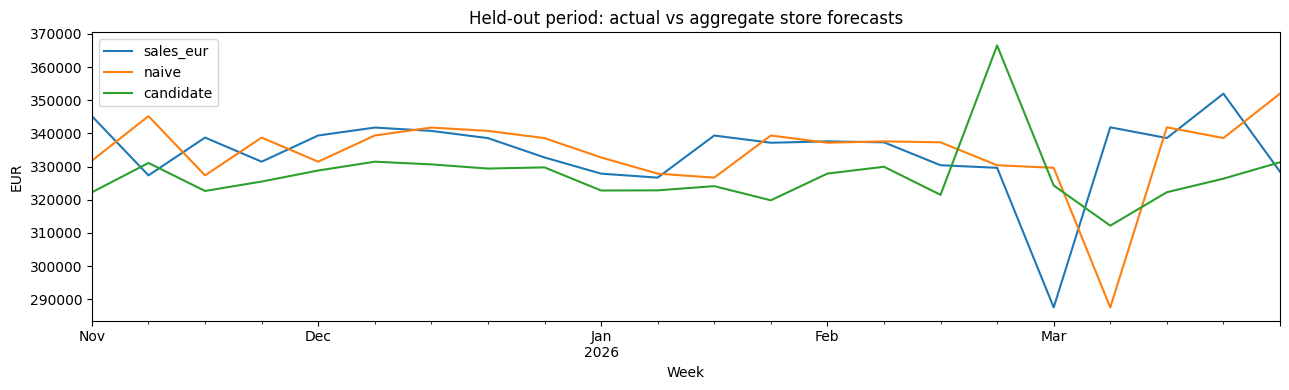

In [7]:
trainval=pd.concat([train,val],ignore_index=True)
final_model=HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=best_leaves,
                    learning_rate=0.05,l2_regularization=10,random_state=42)
final_model.fit(features(trainval),trainval.sales_eur)
eval_df=test[['store_id','week_start','sales_eur']].copy()
eval_df['naive']=test.lag_1.to_numpy()
eval_df['candidate']=final_model.predict(features(test))
comparison=pd.DataFrame({'Naive last week':metrics(eval_df.sales_eur,eval_df.naive),
                         'Candidate model':metrics(eval_df.sales_eur,eval_df.candidate)}).T
comparison['MAE_vs_naive_pct']=100*(comparison.MAE_EUR/comparison.loc['Naive last week','MAE_EUR']-1)
print('Final held-out test results:');display(comparison.round(2))
rows=[]
for store,grp in eval_df.groupby('store_id'):
    a=metrics(grp.sales_eur,grp.naive);b=metrics(grp.sales_eur,grp.candidate)
    rows.append({'store_id':store,'naive_MAE':a['MAE_EUR'],'candidate_MAE':b['MAE_EUR'],
                 'candidate_WAPE_pct':b['WAPE_pct'],'candidate_bias_EUR':b['Bias_EUR'],
                 'MAE_change_pct':100*(b['MAE_EUR']/a['MAE_EUR']-1)})
store_results=pd.DataFrame(rows)
print('Store-level held-out results:');display(store_results.round(2))
fig,ax=plt.subplots(figsize=(13,4))
weekly=eval_df.groupby('week_start')[['sales_eur','naive','candidate']].sum()
weekly.plot(ax=ax);ax.set(title='Held-out period: actual vs aggregate store forecasts',ylabel='EUR',xlabel='Week');plt.tight_layout();plt.show()

In [8]:
naive_mae=comparison.loc['Naive last week','MAE_EUR']
model_mae=comparison.loc['Candidate model','MAE_EUR']
improvement=100*(naive_mae-model_mae)/naive_mae
store_worse=(store_results.MAE_change_pct>0).sum()
print(f'Test MAE improvement versus naive: {improvement:.1f}% (positive means improvement).')
print(f'Stores with worse candidate MAE: {store_worse} of {len(store_results)}.')
if improvement >= 5 and store_worse == 0:
    print('Decision: limited, human-reviewed pilot is defensible; no autonomous deployment.')
elif improvement > 0:
    print('Decision: revise or run a closely monitored shadow pilot; the provisional 5% / store criteria are not fully satisfied.')
else:
    print('Decision: retain naive baseline; revise candidate before any operational pilot.')
print('Interpretation: MAE is the average absolute store-week forecast error in EUR; bias identifies average over/underprediction.')

Test MAE improvement versus naive: 3.4% (positive means improvement).
Stores with worse candidate MAE: 3 of 9.
Decision: revise or run a closely monitored shadow pilot; the provisional 5% / store criteria are not fully satisfied.
Interpretation: MAE is the average absolute store-week forecast error in EUR; bias identifies average over/underprediction.


### Limitations and iteration

- **Data provenance:** no documentation confirms the meaning of duplicate records, whether sales are gross/net, or the causes of high/low sales.
- **Prediction feasibility:** historical sales are assumed finalized by the weekly planning cutoff. If they are not, lags need an additional availability delay.
- **Validation:** one holdout period cannot guarantee future performance; repeat with multiple expanding-window backtests before scaling.
- **Business impact:** no inventory, labor or margin data are provided; no justified EUR benefit or service-level improvement can be calculated.
- **Segment equity:** store-level comparisons reveal whether overall improvement masks deterioration in individual stores; the model should not be rolled out indiscriminately.
- **Data preparation uncertainty:** duplicate-key averaging is provisional and should be confirmed with the source owner.

**Return to earlier CRISP-DM phases:** if store-level errors are unstable, verify key semantics and planning-time availability first; then reconsider lag windows and seasonality. Only after reliable evidence should additional models or externally known promotion schedules be introduced.

## 6. Deployment / Next Iteration

**Proposed operating design (not an implemented production system):** At the end of each completed week, a planning analyst loads validated sales data and generates a one-week-ahead forecast for each existing store. A central planner reviews the store forecasts alongside last-week-sales baseline and uncertainty/error summaries, then passes recommended planning ranges to store managers. Managers can override forecasts with a documented reason (e.g., known local event or supply interruption); model output must not directly trigger automatic procurement or staffing.

**Controls:** check for duplicate keys, missing store-weeks, stale sales, new stores, impossible negative predictions, and input schema changes. Log prediction date, model version, forecasts, overrides and later actual sales. Weekly: compare MAE/WAPE/bias against the naive baseline overall and by store. Monthly: review error trends, drift and manager feedback. Refresh or retrain when sustained deterioration is confirmed, using only historical data available at the cutoff.

**Pause/stop condition (provisional):** pause operational reliance and revert to the naive baseline if data-quality checks fail, or if the candidate's rolling four-week MAE exceeds the naive baseline by more than 10%; escalate repeated store-level underforecasting to human review. These thresholds require business-owner agreement.

**Next experiment:** verify the duplicate rows with the data owner; implement expanding-window backtesting; establish whether pre-announced promotions and planned prices are available; obtain stockout and margin information to evaluate operational value. A shadow pilot should collect manager overrides and actual outcomes before any wider deployment.

## Reproducibility and source boundaries

The source file is the supplied group 03 CSV. The accompanying assignment and assessment structure require all six CRISP-DM phases, a defensible naive forecast, time-aware evaluation, at least three preparation decisions, store-level assessment, business recommendation and a runnable notebook. The data alone do **not** substantiate any operational costs, formal target accuracy, or company-specific policy. Re-run **Kernel → Restart & Run All**, verify all cells execute, and save the notebook with outputs visible before submission.